# Más allá: pruebas de ML y equidad con tamaño y potencia medidos, una referencia por permutación para el cambio y una nula Beta-Binomial para la cobertura

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 02, 04 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- definir el **tamaño** (la tasa de rechazo cuando nada está mal) y la **potencia** (la tasa de rechazo contra un defecto plantado) de una prueba de validación, y dar cada uno con su error estándar de Monte Carlo;
- medir el tamaño de la prueba de cobertura conforme dividida bajo una nula binomial y bajo la nula Beta-Binomial que usa el motor, en tres razones de ventana de prueba a ventana de calibración;
- medir con qué frecuencia una regla de caída fija del AUC se activa en la peor submuestra cuando no hay cambio, y compararla con la referencia por permutación del motor, en tamaño y potencia;
- medir el tamaño y la potencia de la luz de la prueba de situación en los dos puntos de corte ámbar;
- ver las pruebas corregidas en las filas versionadas de los casos C20 y C21, y decir qué respalda esta evidencia y qué no.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import plants as fair_plants
from riskvalidation.fairness import situation
from riskvalidation.ml import conformal, plants, robustness

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

- **Datos simulados nulos y con defecto plantado de los generadores del propio motor**: puntajes intercambiables para la prueba de cobertura, `CovariateShiftPlant` (cambio 0 es la nula, cambio 2 planta un cambio) para la prueba de resiliencia y `ThresholdBiasPlant` (brecha 0 es la nula, brecha 0,8 un sesgo plantado) para la prueba de situación. Sintéticos, con semilla, sin clase de licencia. Cada simulación es lo bastante pequeña para correr en menos de dos minutos en este cuaderno; las corridas mayores pertenecen a los propios conjuntos de tamaño y potencia del motor.
- **Dos documentos versionados** que llevan las pruebas corregidas en uso (propietario: este repositorio): `data/derived/C20/fed-shift.json` (un modelo LightGBM sobre los datos de quiebras polacas de UCI, CC BY 4.0, clase mirror-allowed, bajo desplazamientos sintéticos dimensionados por las carteras corporativas de la Reserva Federal; sus filas conformes guardan ambos valores p y su fila de resiliencia sus 199 sorteos por permutación) y `data/derived/C21/pair-2018-19.json` (la comparación HMDA de Delaware, su fila de prueba de situación con el punto de corte ámbar que usa). La primera celda del Método los abre e imprime la versión del motor que los horneó.

In [2]:
# Abrir los dos documentos versionados e imprimir la versión del motor que horneó cada uno
fed = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
print("C20 fed-shift horneado con riskvalidation", fed["provenance"]["riskvalidation_version"], "| C21 pair-2018-19", hmda["provenance"]["riskvalidation_version"])

C20 fed-shift horneado con riskvalidation 0.8.1 | C21 pair-2018-19 0.8.1


## Método

Una prueba de validación es una regla de decisión, y una regla de decisión tiene tasas de error. Para una prueba que rechaza al nivel $\alpha = 0{,}05$:

$$\text{tamaño} = P(\text{rechazar} \mid \text{nada está mal}), \qquad \text{potencia} = P(\text{rechazar} \mid \text{un defecto de severidad conocida}).$$

Una prueba con un tamaño sobre su nivel nominal levanta falsas alarmas y enseña a un equipo a ignorarla; una prueba de baja potencia pasa por alto lo que se hizo para encontrar. Ambos son propiedades de la regla y de los tamaños de muestra, y ninguno lo enuncia la descripción de las pruebas del dossier. Sobre $R$ simulaciones independientes la tasa de rechazo $\hat{r}$ tiene el error estándar de Monte Carlo $\sqrt{\hat{r}(1-\hat{r})/R}$, que las celdas imprimen junto a cada tasa. Todo sorteo aleatorio tiene semilla.

### Paso 1: el tamaño de la prueba de cobertura, binomial contra Beta-Binomial

Con puntajes intercambiables la cobertura verdadera dada la ventana de calibración es $\mathrm{Beta}(k, n_{\mathrm{cal}}+1-k)$ (cuaderno 04). Una prueba que compara el conteo cubierto $c$ de $m$ puntos de prueba con $\mathrm{Binomial}(m, 1-\alpha)$ trata la cobertura como el número fijo $1-\alpha$ e ignora esa variación; la variación es pequeña cuando $m \ll n_{\mathrm{cal}}$ y grande cuando no. El tamaño aproximado de la prueba binomial es $2\bigl(1-\Phi(1{,}96/\sqrt{1 + m/n_{\mathrm{cal}}})\bigr)$: 5% cuando $m/n_{\mathrm{cal}} \to 0$ y sobre eso en otro caso. El motor devuelve ambos valores p; la celda siguiente saca 1.500 réplicas intercambiables en cada una de tres razones de $m$ a $n_{\mathrm{cal}}$ (0,1, 1 y 4) y cuenta con qué frecuencia cada valor p queda bajo 0,05.

In [3]:
# Tamaño de la prueba de cobertura bajo intercambiabilidad: con qué frecuencia los valores p binomial y Beta-Binomial quedan bajo 0,05
rng = np.random.default_rng(1)
REPS = 1500
conformal_size = {}
print(f'{"n_cal":>6s} {"m":>5s} {"m / n_cal":>9s} | {"tamaño binomial":>16s} {"ee de Monte Carlo":>18s} | {"tamaño Beta-Binomial":>20s} {"ee de Monte Carlo":>18s}')
for n_cal, m in ((20000, 2000), (2000, 2000), (1000, 4000)):
    below_binomial = below_beta = 0
    for _ in range(REPS):
        q = conformal.split_conformal_quantile(rng.random(n_cal), 0.1)
        covered = rng.random(m) <= q
        result = conformal.conformal_coverage(np.column_stack([covered, np.zeros(m, dtype=bool)]), np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
        below_binomial += result.p_value_binomial < 0.05
        below_beta += result.p_value < 0.05
    sizes = (below_binomial / REPS, below_beta / REPS)
    conformal_size[(n_cal, m)] = sizes
    errors = [float(np.sqrt(s * (1 - s) / REPS)) for s in sizes]
    print(f"{n_cal:6d} {m:5d} {m / n_cal:9.1f} | {sizes[0]:16.4f} {errors[0]:18.4f} | {sizes[1]:20.4f} {errors[1]:18.4f}")

 n_cal     m m / n_cal |  tamaño binomial  ee de Monte Carlo | tamaño Beta-Binomial  ee de Monte Carlo
 20000  2000       0.1 |           0.0600             0.0061 |               0.0460             0.0054
  2000  2000       1.0 |           0.1587             0.0094 |               0.0440             0.0053
  1000  4000       4.0 |           0.3893             0.0126 |               0.0427             0.0052


### Paso 2: la prueba de resiliencia, una caída fija contra una referencia por permutación

El cuaderno 02 mostró que la caída del AUC en la peor submuestra según el puntaje de cambio es positiva incluso donde nada se movió, porque esa submuestra es una región del espacio de variables y el AUC en un rango restringido es menor. Una regla que lee la caída contra un corte **fijo** se activa entonces sobre un modelo estable. La celda siguiente mide esto en la planta de cambio con cambio 0 (la nula) y con cambio 2 (un cambio plantado de la primera covariable), sobre 60 réplicas de 600 filas de desarrollo y 250 de evaluación, con el peor 25% como submuestra. En cada réplica registra la caída bruta y el valor p por permutación de la referencia del motor (aquí 39 sorteos en lugar de los 199 por omisión, para mantener corta la simulación; el menor valor p es entonces 0,025). Informa la tasa de falsa alarma de dos cortes fijos (el primero una caída sobre 0,05 puntos de AUC, el segundo sobre 0,10) y de la regla por permutación (p como máximo 0,05), y las mismas tres tasas bajo el cambio plantado, que son las potencias.

In [4]:
# Caída bruta y valor p por permutación de la prueba de la peor submuestra en 60 réplicas con cambio 0 y con cambio 2
def replicate_shift(shift, replications, draws):
    drops, p_values = [], []
    for i in range(replications):
        plant = plants.CovariateShiftPlant(n=600, shift=shift, features=[0], seed=1000 + i)
        d = plant.sample()
        x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
        score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=i)
        try:
            reference = robustness.shift_development_reference(plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, draws, seed=i)
        except robustness.SingleClassSubsampleError:
            continue
        drops.append(reference.observed_drop)
        p_values.append(reference.p_value)
    return np.array(drops), np.array(p_values)


shift_rates = {}
print(f'{"cambio":>6s} {"réplicas":>12s} {"caída media":>12s} {"pct. 95":>9s} | {"caída sobre el primer corte":>26s} {"caída sobre el segundo corte":>27s} {"p por permutación como máximo el nivel":>40s}')
for shift in (0.0, 2.0):
    drops, p_values = replicate_shift(shift, 60, 39)
    rates = ((drops > 0.05).mean(), (drops > 0.10).mean(), (p_values <= 0.05).mean())
    shift_rates[shift] = (rates, len(drops))
    print(f"{shift:6.1f} {len(drops):12d} {drops.mean():12.4f} {np.percentile(drops, 95):9.4f} | {rates[0]:26.4f} {rates[1]:27.4f} {rates[2]:40.4f}")
print("ee de Monte Carlo de una tasa cerca del nivel nominal con 60 réplicas:", round(float(np.sqrt(0.05 * 0.95 / 60)), 4))

cambio     réplicas  caída media   pct. 95 | caída sobre el primer corte caída sobre el segundo corte   p por permutación como máximo el nivel
   0.0           60       0.0119    0.1203 |                     0.2000                      0.0833                                   0.0667
   2.0           60       0.1348    0.2778 |                     0.8500                      0.6667                                   0.5000
ee de Monte Carlo de una tasa cerca del nivel nominal con 60 réplicas: 0.0281


### Paso 3: la luz de la prueba de situación, en dos puntos de corte

La prueba de situación devuelve, para los denunciantes del grupo protegido, cuántos son significativos al nivel $\alpha = 0{,}05$ con el intervalo de Wald unilateral del cuaderno 07. Incluso sin efecto de grupo algunos denunciantes son significativos por azar, así que la luz lee la **proporción** de denunciantes significativos contra un punto de corte: verde hasta el corte, ámbar sobre él, nunca roja. Un punto de corte es una convención, y la manera de elegirlo es medir la distribución de la proporción bajo la nula y bajo un sesgo plantado. La celda siguiente saca 200 réplicas de 400 solicitantes con la planta de sesgo de umbral del motor con brecha 0 (la nula: la decisión depende solo de las covariables) y brecha 0,8 (el grupo protegido aprobado con un punto de corte menor), corre la prueba ceteris paribus con $k = 30$ e informa con qué frecuencia la proporción supera el primer corte (0,10) y el segundo (0,20), en el orden de las dos columnas.

In [5]:
# Proporción de denunciantes significativos en 200 réplicas con brecha 0 y brecha 0,8, y con qué frecuencia supera cada punto de corte
situation_rates = {}
print(f'{"brecha":>5s} {"réplicas":>12s} {"proporción media":>16s} | {"proporción sobre el primer corte":>36s} {"proporción sobre el segundo corte":>37s}')
for gap in (0.0, 0.8):
    shares = []
    for i in range(200):
        draw = fair_plants.ThresholdBiasPlant(n=400, gap=gap, seed=2000 + i).draw_default()
        result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
        shares.append(result.n_significant / result.n_complainants)
    shares = np.array(shares)
    situation_rates[gap] = ((shares > 0.10).mean(), (shares > 0.20).mean())
    print(f"{gap:5.1f} {len(shares):12d} {shares.mean():16.4f} | {situation_rates[gap][0]:36.4f} {situation_rates[gap][1]:37.4f}")

brecha     réplicas proporción media |     proporción sobre el primer corte     proporción sobre el segundo corte
  0.0          200           0.0398 |                               0.0850                                0.0150
  0.8          200           0.7338 |                               1.0000                                1.0000


## Estado del arte

La práctica que encontró la investigación para estas tres pruebas, con su brecha:

- **Cobertura conforme.** El dossier (C.7, l.1019 a 1028) prescribe la cobertura empírica sobre datos fuera de tiempo contra $1-\alpha$ "(prueba binomial sobre indicadores de cobertura)". Angelopoulos y Bates (2021) y Vovk, Gammerman y Shafer (2022) dan la garantía $P(Y \in C(X)) \ge 1-\alpha$ bajo intercambiabilidad; no describen el tamaño de una prueba de validación construida sobre una ventana de calibración finita. MAPIE y PiML (Reliability) implementan la forma dividida.
- **Resiliencia al cambio.** La prueba Resilience de PiML y el dossier (C.7, l.1013 a 1015) evalúan el desempeño en la peor submuestra según un puntaje de cambio y en ventanas fuera de tiempo; el dossier da la construcción y ninguna regla para decidir que una caída es demasiado grande.
- **Pruebas de situación.** Alvarez y Ruggieri (2025) dan el estadístico y el intervalo unilateral y dejan al usuario la decisión de cuántos denunciantes significativos son demasiados.

Ninguna de las herramientas del cuaderno 08 informa las tasas de rechazo de estas reglas sobre datos de verdad conocida.

## Más allá del estado del arte

Lo que el producto agrega, reclamado como **BS-10** en el SDD: las tres pruebas llevan las correcciones que decidieron las revisiones del motor, y el producto muestra, con las funciones del propio motor sobre datos plantados, la tasa de error que cada corrección elimina.

1. La prueba de cobertura lee la ley **Beta-Binomial** del conteo cubierto dado el tamaño de calibración, y conserva el valor p binomial del dossier a su lado.
2. La luz de resiliencia lee una **referencia por permutación** de las filas de desarrollo (199 sorteos por omisión), no una caída fija.
3. El punto de corte ámbar de la prueba de situación es **0,20**, fijado sobre un tamaño y una potencia medidos.

Las filas versionadas muestran las pruebas corregidas en uso. La celda siguiente imprime las ventanas conformes de la variante de la Reserva Federal con ambos valores p, la fila de resiliencia con sus sorteos y su resumen nulo, y la fila de prueba de situación con el punto de corte que usó.

In [6]:
# Las filas corregidas versionadas: ambos valores p conformes, los sorteos de resiliencia y el punto de corte de la prueba de situación
for t in [t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage"]:
    x = t["extras"]
    print(f'{t["segment"]:28s} n_cal {x["n_cal"]} m {t["n"]:6d} p Beta-Binomial {t["p_value"]:.3g} binomial {x["p_value_binomial"]:.3g} luz {t["light"]}')
row = next(t for t in fed["tests"] if t["test_id"] == "ml.shift_resilience")
print("resiliencia:", row["segment"], "| caída", round(row["metric"], 4), "| p", row["p_value"], "| sorteos", row["extras"]["shift_permutations"], "| media nula", round(row["extras"]["null_mean"], 4), "| percentil 95 nulo", round(row["extras"]["null_p95"], 4), "|", row["light"])
st = next(t for t in hmda["tests"] if t["test_id"] == "fair.situation_testing")
print("prueba de situación: proporción de denunciantes significativos", round(st["metric"], 4), "| puntos de corte", st["extras"]["thresholds"]["amber"], "|", st["light"])

window:baseline              n_cal 1471 m   3151 p Beta-Binomial 0.523 binomial 0.313 luz green
window:fed-higher-risk-x0.25 n_cal 1471 m   3151 p Beta-Binomial 2.13e-35 binomial 3.69e-127 luz red
window:fed-higher-risk-x0.5  n_cal 1471 m   3151 p Beta-Binomial 4.56e-52 binomial 1.19e-194 luz red
window:fed-higher-risk-x1    n_cal 1471 m   3151 p Beta-Binomial 0.0372 binomial 0.000258 luz amber
window:pooled                n_cal 1471 m  12604 p Beta-Binomial 2.86e-20 binomial 2.16e-207 luz red
resiliencia: fed-higher-risk-x1 | caída 0.0857 | p 0.005 | sorteos 199 | media nula 0.0007 | percentil 95 nulo 0.0243 | red
prueba de situación: proporción de denunciantes significativos 0.2629 | puntos de corte 0.2 | amber


### La evidencia, dibujada

Izquierda: el tamaño de la prueba de cobertura con la nula binomial y con la Beta-Binomial en las tres razones de ventana, contra el 0,05 nominal. Derecha: la tasa de falsa alarma y la potencia de las tres reglas de resiliencia, y de los dos puntos de corte de la prueba de situación.

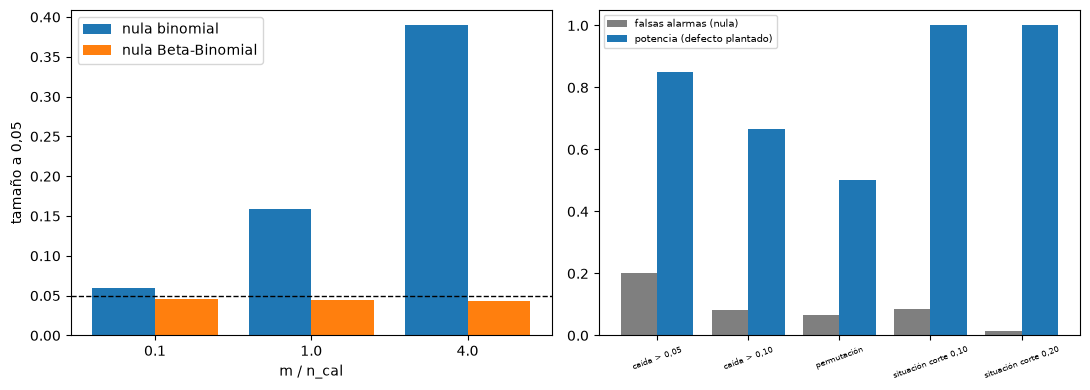

In [7]:
# Izquierda: tamaño de la prueba de cobertura por razón de ventana; derecha: tasa de falsa alarma (gris) y potencia (azul) de las reglas de resiliencia y de situación
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.0))
ratios = [f"{m / n:.1f}" for n, m in conformal_size]
position = np.arange(len(ratios))
left.bar(position - 0.2, [s[0] for s in conformal_size.values()], width=0.4, label="nula binomial")
left.bar(position + 0.2, [s[1] for s in conformal_size.values()], width=0.4, label="nula Beta-Binomial")
left.axhline(0.05, color="black", linestyle="--", linewidth=1)
left.set_xticks(position)
left.set_xticklabels(ratios)
left.set_xlabel("m / n_cal")
left.set_ylabel("tamaño a 0,05")
left.legend()
names = ["caída > 0,05", "caída > 0,10", "permutación", "situación corte 0,10", "situación corte 0,20"]
null_rates = list(shift_rates[0.0][0]) + list(situation_rates[0.0])
power_rates = list(shift_rates[2.0][0]) + list(situation_rates[0.8])
index = np.arange(len(names))
right.bar(index - 0.2, null_rates, width=0.4, color="tab:gray", label="falsas alarmas (nula)")
right.bar(index + 0.2, power_rates, width=0.4, color="tab:blue", label="potencia (defecto plantado)")
right.set_xticks(index)
right.set_xticklabels(names, fontsize=6, rotation=20)
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **La nula binomial hace que la prueba de cobertura rechace demasiado una vez que la ventana de prueba no es pequeña.** Con datos intercambiables y el nivel nominal 0,05, el valor p binomial cae bajo 0,05 en 0,0600 de las réplicas cuando la ventana de prueba es un décimo de la de calibración (error estándar 0,0061), en 0,1587 cuando las dos ventanas son iguales (0,0094) y en 0,3893 cuando la ventana de prueba es cuatro veces la de calibración (0,0126). El valor p Beta-Binomial del motor cae bajo 0,05 en 0,0460, 0,0440 y 0,0427 de ellas (errores estándar de 0,0052 a 0,0054): bajo el nivel nominal en las tres razones, nunca sobre él. Las ventanas versionadas de la Reserva Federal tienen una ventana de calibración de 1.471 empresas contra ventanas de prueba de 3.151 y 12.604, el régimen donde las dos difieren: la ventana base da 0,523 (Beta-Binomial) y 0,313 (binomial), y para la cobertura de 0,8800 del desplazamiento completo el valor p Beta-Binomial es 0,0372 (ámbar) mientras el binomial es 0,000258.
- **Una regla de caída fija se activa sobre un modelo estable; la referencia por permutación no.** Sin cambio, la caída bruta del peor cuarto según el puntaje de cambio tiene una media de 0,0119 y un percentil 95 de 0,1203 sobre 60 réplicas. Una regla "caída sobre 0,05" levanta una falsa alarma en 0,2000 de ellas y "caída sobre 0,10" en 0,0833; la regla por permutación (p como máximo 0,05, con 39 sorteos aquí) en 0,0667, que está dentro del error estándar (0,0281) del nivel nominal. Contra el cambio plantado de 2 desviaciones estándar las tres reglas lo detectan en 0,8500, 0,6667 y 0,5000 de las réplicas. Así, en este diseño pequeño la referencia por permutación mantiene la tasa de falsa alarma cerca de su nivel y lo paga en potencia, porque 250 filas de evaluación y 39 sorteos vuelven gruesa la referencia; los cortes fijos detectan más porque también se activan cuando no hay nada. Los 199 sorteos por omisión del motor y muestras mayores reducen ese costo, y este cuaderno no lo mide. La fila versionada de la Reserva Federal lee una caída de 0,0857 contra una nula que promedia 0,0007 y tiene un percentil 95 de 0,0243 sobre 199 sorteos: p = 0,005, rojo.
- **El punto de corte 0,20 de la luz de situación elimina la mayoría de las falsas alarmas sin costo en potencia en este diseño.** Sin efecto de grupo la proporción de denunciantes significativos promedia 0,0398, y supera el corte antiguo 0,10 en 0,0850 de las 200 réplicas y el corte 0,20 en 0,0150; con el sesgo plantado la proporción promedia 0,7338 y supera ambos cortes en toda réplica. La medición documentada del propio motor (un tamaño de 0,039 en 0,20 y 0,194 en 0,10) usa otro protocolo y no se reproduce aquí: la dirección coincide, la magnitud no. La fila versionada de Delaware 2018 tiene una proporción de 0,2629 contra el corte 0,2: ámbar.
- **Lo que esta evidencia respalda para BS-10.** Las tres correcciones están en uso en los documentos versionados (ambos valores p conformes lado a lado, 199 sorteos por permutación, el corte 0,2), y las funciones del propio motor sobre datos plantados muestran el tamaño que corrige cada una: 0,1587 y 0,3893 para la prueba de cobertura binomial contra cerca de 0,044 para la Beta-Binomial, 0,2000 y 0,0833 para cortes de caída fijos contra 0,0667 para la referencia por permutación, 0,0850 contra 0,0150 para los dos cortes de situación. Todas las filas versionadas se hornearon con riskvalidation 0.8.1.

Lo que los resultados no muestran: las simulaciones son pequeñas (1.500, 60 y 200 réplicas) y cada tasa lleva el error estándar impreso a su lado; el diseño de cambio tiene pocas filas y 39 sorteos; los conjuntos de tamaño y potencia del propio motor, que son mayores, están en el repositorio del motor y no se corren aquí; los defectos plantados son sintéticos; y una prueba con buen tamaño y potencia sobre una planta no dice todavía nada de una cartera real.

## Resumen

- La nula binomial hace que la prueba de cobertura rechace en 0,0600, 0,1587 y 0,3893 de las réplicas intercambiables con razones de prueba a calibración de 0,1, 1 y 4, mientras la nula Beta-Binomial del motor se queda en 0,0460, 0,0440 y 0,0427.
- Una regla de caída fija del AUC en la peor submuestra levanta una falsa alarma en 0,2000 y 0,0833 de las réplicas sin cambio; la referencia por permutación en 0,0667, con un costo en potencia en este diseño pequeño.
- El punto de corte ámbar 0,20 de la prueba de situación levanta una falsa alarma en 0,0150 de las réplicas nulas contra 0,0850 del corte 0,10, y ambos detectan el sesgo plantado en toda réplica.
- Las filas versionadas de C20 y C21 llevan las correcciones en uso: ambos valores p conformes lado a lado, 199 sorteos por permutación y el corte 0,2, horneadas con riskvalidation 0.8.1.
- Cada tasa se imprime con su error estándar de Monte Carlo; las simulaciones son pequeñas, las plantas sintéticas, y los conjuntos de tamaño y potencia mayores del motor no se corren aquí.

**Qué probar después.** El tema 14 mide el tamaño y la potencia de todo el catálogo del motor sobre defectos plantados, con el mismo método a mayor escala.

## Referencias

- Angelopoulos, A. N. y Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- PiML-Toolbox (Apache-2.0), pruebas de resultados WeakSpot, Overfit, Reliability, Robustness y Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- Phipson, B. y Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Alvarez, J. M. y Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Zieba, M., Tomczak, S. K. y Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data